 # STEP 0: IMPORT ALL REQUIRED LIBRARIES



 **What we do:** Import Python packages for data handling, visualization, and ML.



 **Why:** We need tools to read data, create charts, build models, and evaluate them.



 | Library | Purpose |

 |---------|---------|

 | pandas | Data tables and CSV reading |

 | numpy | Math operations and arrays |

 | matplotlib/seaborn | Charts and graphs |

 | sklearn | Machine learning algorithms |

 | xgboost/lightgbm | Advanced tree models |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import boxcox1p
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 60)
print("HOUSE PRICES ML PROJECT")
print("=" * 60)


HOUSE PRICES ML PROJECT


 # STEP 1: LOAD AND UNDERSTAND THE DATASET



 **What we do:** Read train.csv and test.csv files.



 **Why:** Before building models, we MUST know:

 - How much data we have

 - What columns exist

 - What data types they are

 - What our target variable looks like



 **Dataset Info:**

 - train.csv: 1,460 houses, 80 features + SalePrice (target)

 - test.csv: 1,459 houses, 80 features (no target - we predict this!)

In [2]:
train_df = pd.read_csv('../data/raw/train.csv')
test_df = pd.read_csv('../data/raw/test.csv')

print("\n" + "=" * 60)
print("STEP 1: DATASET OVERVIEW")
print("=" * 60)
print(f"Training Data: {train_df.shape[0]} rows, {train_df.shape[1]} columns")
print(f"Test Data: {test_df.shape[0]} rows, {test_df.shape[1]} columns")
print("\nFirst 5 rows:")
print(train_df.head())
print("\nColumn Info:")
print(train_df.info())
print("\nNumerical Summary:")
print(train_df.describe())
print("\nTarget Variable (SalePrice) Stats:")
print(train_df['SalePrice'].describe())



STEP 1: DATASET OVERVIEW
Training Data: 1460 rows, 81 columns
Test Data: 1459 rows, 80 columns

First 5 rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0  

 # STEP 2: EXPLORATORY DATA ANALYSIS (EDA)



 **What is EDA?** Exploring data visually and statistically to find patterns.



 **Why EDA matters:**

 - Reveals data quality issues (missing values, outliers)

 - Shows relationships between features and price

 - Guides preprocessing decisions

 ## 2.1 Target Variable Distribution



 **What we check:** Is SalePrice normally distributed?



 **Why:** ML models prefer normal distributions. If data is skewed, we transform it.



 **Finding:** SalePrice is right-skewed (long tail of expensive houses).

 **Solution:** Apply log transformation to make it normal.

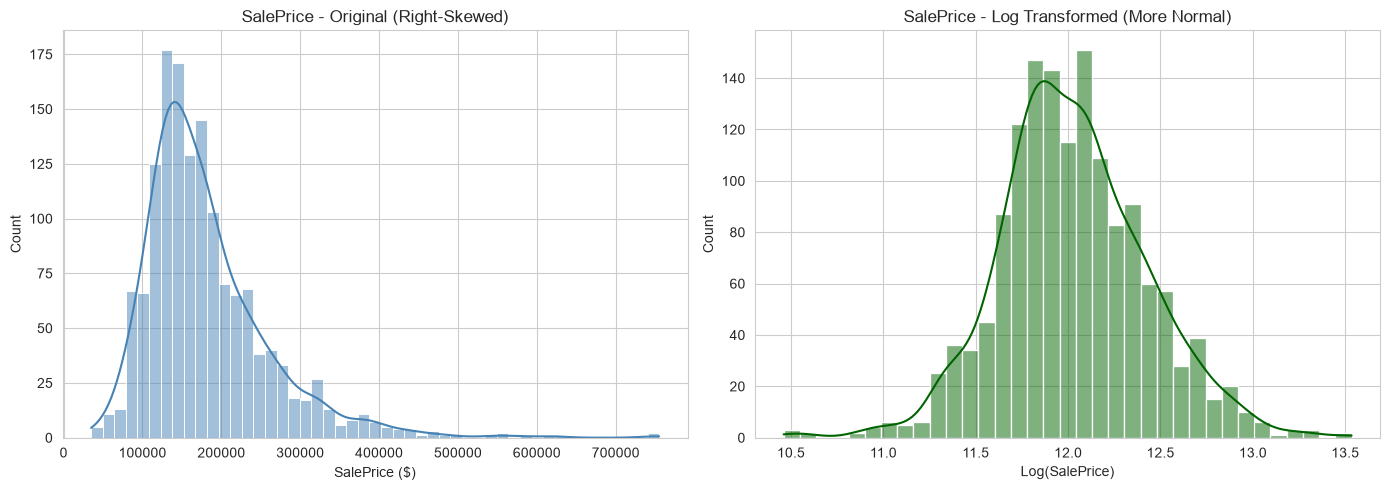


Original Skewness: 1.8829
Log Skewness: 0.1213
Log transformation makes the data more normal (skewness closer to 0).


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original distribution
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('SalePrice - Original (Right-Skewed)')
axes[0].set_xlabel('SalePrice ($)')

# Log-transformed distribution
sns.histplot(np.log1p(train_df['SalePrice']), kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title('SalePrice - Log Transformed (More Normal)')
axes[1].set_xlabel('Log(SalePrice)')

plt.tight_layout()
plt.savefig('01_target_distribution.png', dpi=150)
plt.show()

print(f"\nOriginal Skewness: {train_df['SalePrice'].skew():.4f}")
print(f"Log Skewness: {np.log1p(train_df['SalePrice']).skew():.4f}")
print("Log transformation makes the data more normal (skewness closer to 0).")


 ## 2.2 Missing Values Analysis



 **What we check:** Which columns have missing values and how many?



 **Why:** ML models cannot handle missing values. We must fill or drop them.



 **Key Finding:** PoolQC has 99.5% missing - because most houses have no pool.


--- Missing Values in Training Data ---
PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtExposure     2.602740
BsmtFinType2     2.602740
BsmtQual         2.534247
BsmtCond         2.534247
BsmtFinType1     2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64


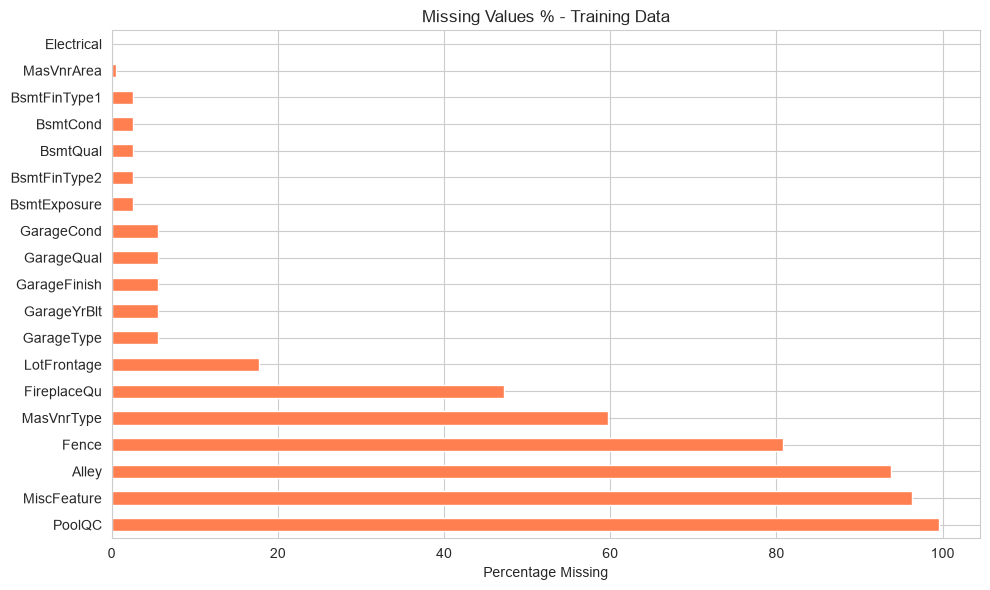

In [4]:
train_missing = (train_df.isnull().sum() / len(train_df) * 100)
train_missing = train_missing[train_missing > 0].sort_values(ascending=False)

print("\n--- Missing Values in Training Data ---")
print(train_missing)

plt.figure(figsize=(10, 6))
train_missing.plot(kind='barh', color='coral')
plt.title('Missing Values % - Training Data')
plt.xlabel('Percentage Missing')
plt.tight_layout()
plt.savefig('02_missing_values.png', dpi=150)
plt.show()


 ## 2.3 Correlation Analysis



 **What is correlation?** Measures how strongly two variables move together.

 - +1 = perfect positive (as one goes up, other goes up)

 - -1 = perfect negative

 - 0 = no relationship



 **Top predictors:** OverallQual, GrLivArea, GarageCars, GarageArea


--- Top 15 Features Correlated with SalePrice ---
SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
LotFrontage     0.351799
Name: SalePrice, dtype: float64


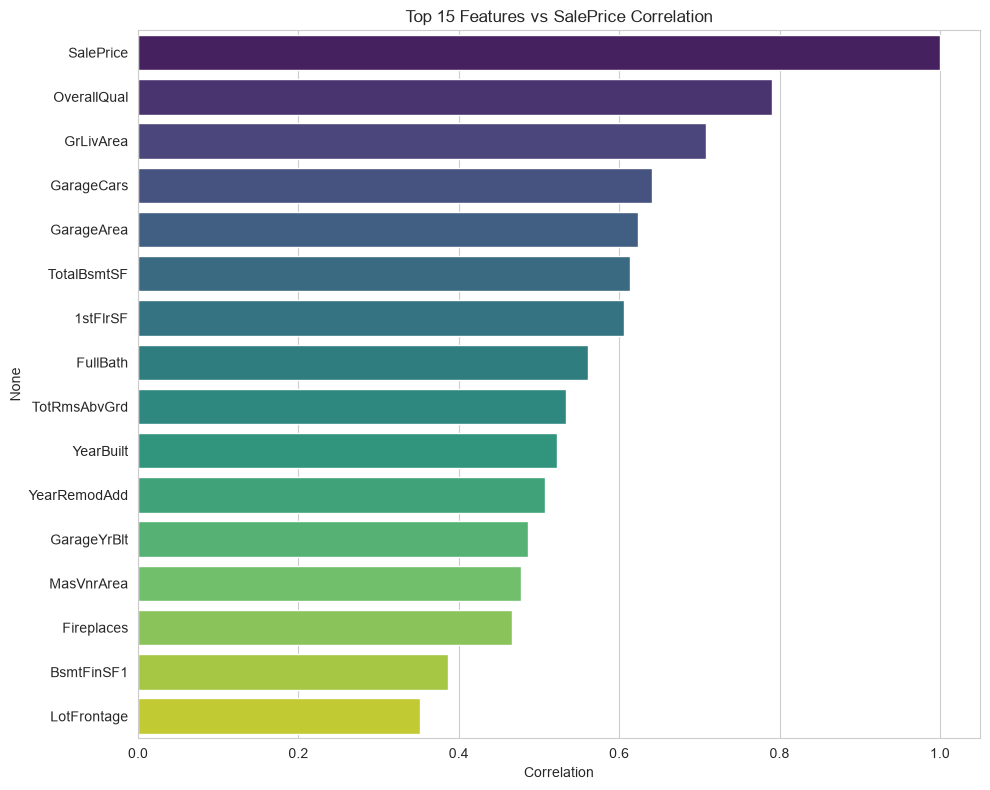

In [5]:
correlation = train_df.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
print("\n--- Top 15 Features Correlated with SalePrice ---")
print(correlation.head(16))

plt.figure(figsize=(10, 8))
top_corr = correlation.head(16)
sns.barplot(x=top_corr.values, y=top_corr.index, palette='viridis')
plt.title('Top 15 Features vs SalePrice Correlation')
plt.xlabel('Correlation')
plt.tight_layout()
plt.savefig('03_correlation.png', dpi=150)
plt.show()


 ## 2.4 Key Feature Relationships



 Visualizing how important features relate to price.

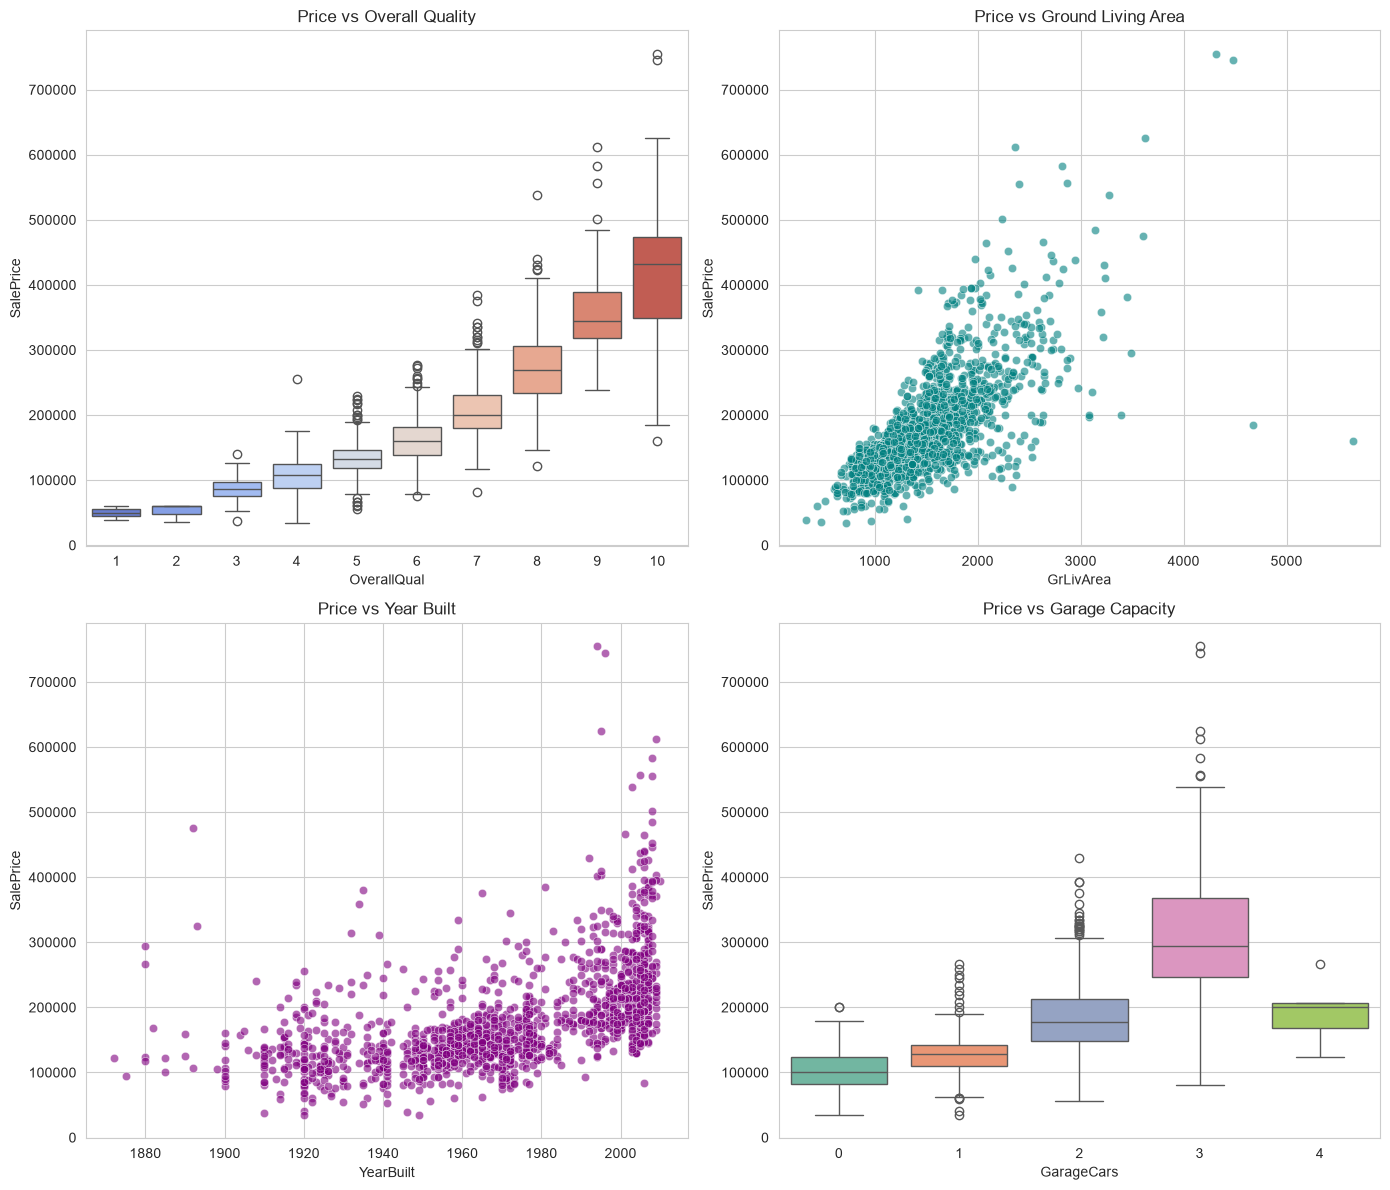

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sns.boxplot(x='OverallQual', y='SalePrice', data=train_df, ax=axes[0,0], palette='coolwarm')
axes[0,0].set_title('Price vs Overall Quality')

sns.scatterplot(x='GrLivArea', y='SalePrice', data=train_df, ax=axes[0,1], alpha=0.6, color='teal')
axes[0,1].set_title('Price vs Ground Living Area')

sns.scatterplot(x='YearBuilt', y='SalePrice', data=train_df, ax=axes[1,0], alpha=0.6, color='purple')
axes[1,0].set_title('Price vs Year Built')

sns.boxplot(x='GarageCars', y='SalePrice', data=train_df, ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Price vs Garage Capacity')

plt.tight_layout()
plt.savefig('04_feature_relationships.png', dpi=150)
plt.show()


 # STEP 3: DATA PREPROCESSING



 **What is preprocessing?** Cleaning and preparing raw data for ML models.



 **Steps:**

 1. Separate target from features

 2. Remove outliers

 3. Handle missing values

 4. Create new features (feature engineering)

 5. Transform skewed features

 6. Encode categories to numbers

 7. Scale features to same range

 ## 3.1 Save Target and Drop ID



 - Separate SalePrice as our target variable

 - Apply log transformation (explained in EDA)

 - Drop 'Id' - it's just a row number, not predictive

In [7]:
train_ID = train_df['Id']
test_ID = test_df['Id']

# Log transform target: log(1 + SalePrice)
y_train = np.log1p(train_df['SalePrice'])

# Drop Id and SalePrice from features
train_df.drop(['Id', 'SalePrice'], axis=1, inplace=True)
test_df.drop(['Id'], axis=1, inplace=True)

print(f"Target shape: {y_train.shape}")
print(f"Train features: {train_df.shape}")
print(f"Test features: {test_df.shape}")


Target shape: (1460,)
Train features: (1460, 79)
Test features: (1459, 79)


 ## 3.2 Outlier Detection and Removal



 **What are outliers?** Data points that don't follow the normal pattern.



 **Why remove?** They can distort the model and reduce accuracy.



 **Method:** We found 2 houses with GrLivArea > 4000 sq ft but very low prices.

 These are likely data errors or special sales.

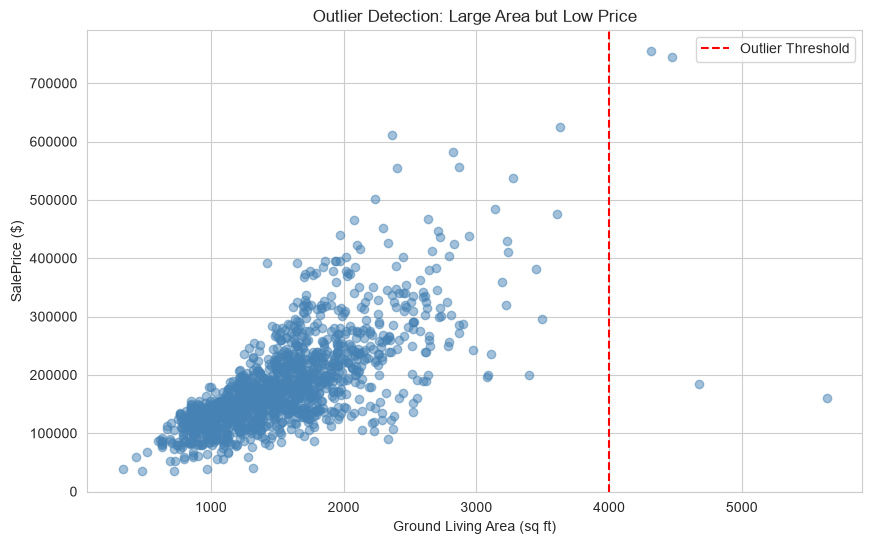

Outliers found: 2
Shape after outlier removal: (1458, 79)


In [8]:
# Temporarily add SalePrice back for visualization
train_df['SalePrice'] = np.expm1(y_train)

plt.figure(figsize=(10, 6))
plt.scatter(train_df['GrLivArea'], train_df['SalePrice'], alpha=0.5, c='steelblue')
plt.xlabel('Ground Living Area (sq ft)')
plt.ylabel('SalePrice ($)')
plt.title('Outlier Detection: Large Area but Low Price')
plt.axvline(x=4000, color='red', linestyle='--', label='Outlier Threshold')
plt.legend()
plt.savefig('05_outliers.png', dpi=150)
plt.show()

# Remove outliers
outliers = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
print(f"Outliers found: {outliers.sum()}")

train_df = train_df[~outliers]
y_train = y_train[~outliers]
train_df.drop(['SalePrice'], axis=1, inplace=True)

print(f"Shape after outlier removal: {train_df.shape}")


 ## 3.3 Combine Train and Test



 **Why combine?** To apply the SAME preprocessing to both datasets.

 If we process separately, we might fill missing values differently.

In [9]:
ntrain = train_df.shape[0]
ntest = test_df.shape[0]
all_data = pd.concat([train_df, test_df], axis=0, sort=False)
print(f"Combined shape: {all_data.shape}")


Combined shape: (2917, 79)


 ## 3.4 Handle Missing Values



 **Strategy depends on what "missing" means:**



 | Feature | Missing Means | Fill With |

 |---------|--------------|-----------|

 | PoolQC, Fence | No pool/fence | "None" |

 | GarageArea | No garage | 0 |

 | LotFrontage | Unknown | Neighborhood median |

 | MSZoning | Unknown | Most common value (mode) |

In [10]:
# Categorical: NA means "None" (feature doesn't exist)
none_features = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
               'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
               'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 
               'BsmtFinType2', 'MasVnrType']
for col in none_features:
    all_data[col] = all_data[col].fillna('None')

# Numerical: NA means 0 (no area/count)
zero_features = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 
                 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 
                 'BsmtHalfBath', 'MasVnrArea']
for col in zero_features:
    all_data[col] = all_data[col].fillna(0)

# LotFrontage: fill with median of same neighborhood
all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

# Remaining: fill with mode (most common)
mode_features = ['MSZoning', 'Functional', 'Electrical', 'KitchenQual', 
                 'Exterior1st', 'Exterior2nd', 'SaleType', 'Utilities']
for col in mode_features:
    all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

# MSSubClass is categorical (building type codes)
all_data['MSSubClass'] = all_data['MSSubClass'].astype(str)

print(f"Missing values after: {all_data.isnull().sum().sum()}")


Missing values after: 0


 ## 3.5 Feature Engineering



 **What:** Creating new features from existing ones.



 **Why:** New features can capture relationships better than raw data.



 | New Feature | What It Captures |

 |-------------|-----------------|

 | TotalSF | Total living space |

 | Total_Bathrooms | All bathrooms combined |

 | HouseAge | How old the house is |

 | HasPool, HasGarage | Presence of amenities |

 | QualSF | Quality × Size interaction |

In [11]:
all_data['TotalSF'] = all_data['TotalBsmtSF'] + all_data['1stFlrSF'] + all_data['2ndFlrSF']
all_data['Total_Bathrooms'] = (all_data['FullBath'] + 0.5*all_data['HalfBath'] +
                                all_data['BsmtFullBath'] + 0.5*all_data['BsmtHalfBath'])
all_data['TotalPorchSF'] = (all_data['OpenPorchSF'] + all_data['3SsnPorch'] +
                            all_data['EnclosedPorch'] + all_data['ScreenPorch'] +
                            all_data['WoodDeckSF'])
all_data['HouseAge'] = all_data['YrSold'] - all_data['YearBuilt']
all_data['RemodAge'] = all_data['YrSold'] - all_data['YearRemodAdd']
all_data['HasPool'] = (all_data['PoolArea'] > 0).astype(int)
all_data['Has2ndFloor'] = (all_data['2ndFlrSF'] > 0).astype(int)
all_data['HasGarage'] = (all_data['GarageArea'] > 0).astype(int)
all_data['HasBsmt'] = (all_data['TotalBsmtSF'] > 0).astype(int)
all_data['HasFireplace'] = (all_data['Fireplaces'] > 0).astype(int)
all_data['QualSF'] = all_data['OverallQual'] * all_data['TotalSF']

print(f"Total features after engineering: {all_data.shape[1]}")


Total features after engineering: 90


 ## 3.6 Transform Skewed Features



 **Why:** Skewed features hurt linear models. We make them normal.



 **Method:** Box-Cox transformation with lambda=0.15

In [12]:
numeric_feats = all_data.select_dtypes(include=[np.number]).columns

skewed_feats = all_data[numeric_feats].apply(
    lambda x: x.dropna().skew()
).sort_values(ascending=False)

skewness = skewed_feats[abs(skewed_feats) > 0.75]

for feat in skewness.index:
    all_data[feat] = boxcox1p(all_data[feat], 0.15)

print(f"Transformed {len(skewness)} skewed features")

Transformed 26 skewed features


 ## 3.7 Encode Categorical Variables



 **Why:** ML models only understand numbers, not text.



 **Method:** Label Encoding - each category gets a number.

In [13]:
categorical_features = all_data.select_dtypes(include=['object']).columns
le = LabelEncoder()
for col in categorical_features:
    all_data[col] = le.fit_transform(all_data[col].astype(str))

print(f"Encoded {len(categorical_features)} categorical features")


Encoded 44 categorical features


 ## 3.8 Feature Scaling



 **Why:** Features have different scales (sq ft vs years vs counts).

 Scaling helps regularized models and distance-based algorithms.



 **Method:** RobustScaler - uses median, resistant to outliers.

In [14]:
scaler = RobustScaler()
all_data_scaled = pd.DataFrame(
    scaler.fit_transform(all_data),
    columns=all_data.columns,
    index=all_data.index
)

# Separate back into train and test
X_train = all_data_scaled[:ntrain]
X_test = all_data_scaled[ntrain:]

print(f"Final: X_train {X_train.shape}, X_test {X_test.shape}")


Final: X_train (1458, 90), X_test (1459, 90)


 # STEP 4: MODEL BUILDING AND EVALUATION



 **What:** Build multiple ML models and compare them.



 **Models:** Ridge, Lasso, ElasticNet, Random Forest, Gradient Boosting, XGBoost, LightGBM



 **Evaluation:** 5-Fold Cross-Validation with RMSE

In [15]:
# Cross-validation setup
kf = KFold(n_splits=5, shuffle=True, random_state=42)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def cv_rmse(model, X, y):
    scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    return np.sqrt(-scores)

# Define all models
models = {
    'Ridge': Ridge(alpha=10, random_state=42),
    'Lasso': Lasso(alpha=0.0005, random_state=42, max_iter=10000),
    'ElasticNet': ElasticNet(alpha=0.0005, l1_ratio=0.9, random_state=42, max_iter=10000),
    'RandomForest': RandomForestRegressor(n_estimators=300, max_depth=15, 
                                          min_samples_split=5, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                   max_depth=4, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                            subsample=0.7, random_state=42),
    'LightGBM': LGBMRegressor(n_estimators=300, learning_rate=0.05, 
                              num_leaves=5, random_state=42)
}


 ## 4.1 Cross-Validation Results



 Run each model through 5-fold CV and compare RMSE.

 Lower RMSE = better predictions.


--- 5-Fold Cross-Validation Results ---
Model                Mean RMSE    Std RMSE    
--------------------------------------------------
Ridge                0.11925      0.00867     
Lasso                0.11870      0.00915     
ElasticNet           0.11870      0.00916     
RandomForest         0.13445      0.00764     
GradientBoosting     0.12336      0.00695     
XGBoost              0.11797      0.00483     
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001004 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4050
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 82
[LightGBM] [Info] Start training from score 12.023362
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001015 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4051
[LightGBM] [Info] Number of data points i

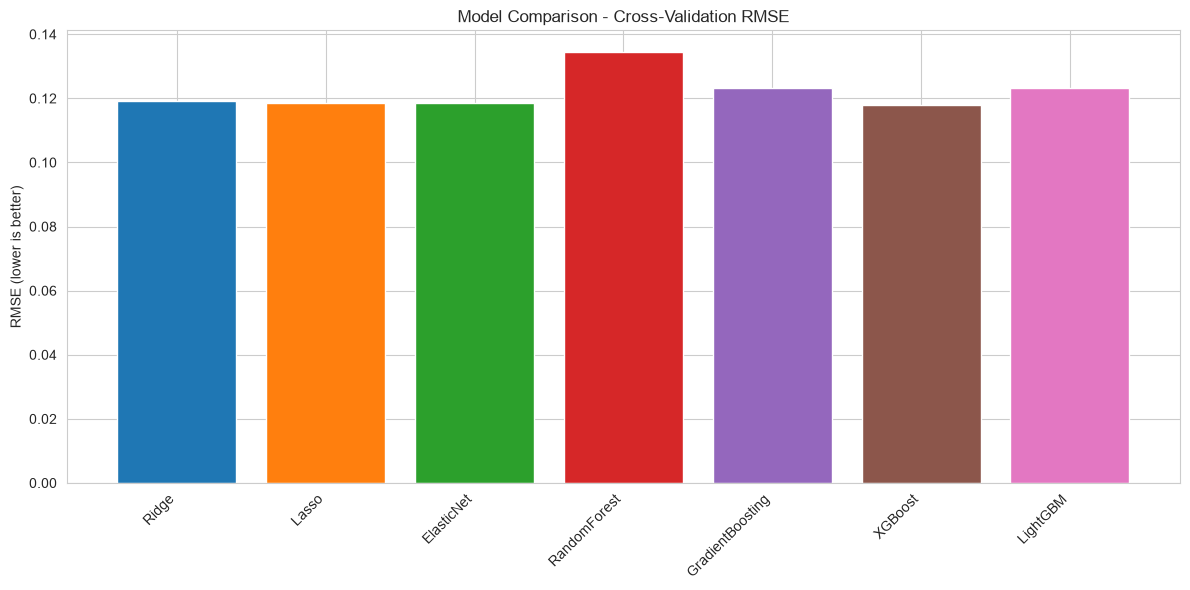

In [16]:
print("\n--- 5-Fold Cross-Validation Results ---")
print(f"{'Model':<20} {'Mean RMSE':<12} {'Std RMSE':<12}")
print("-" * 50)

cv_results = {}
for name, model in models.items():
    scores = cv_rmse(model, X_train, y_train)
    cv_results[name] = scores
    print(f"{name:<20} {scores.mean():<12.5f} {scores.std():<12.5f}")

# Plot comparison
plt.figure(figsize=(12, 6))
cv_means = [cv_results[name].mean() for name in models.keys()]
model_names = list(models.keys())
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
plt.bar(model_names, cv_means, color=colors)
plt.ylabel('RMSE (lower is better)')
plt.title('Model Comparison - Cross-Validation RMSE')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('06_model_comparison.png', dpi=150)
plt.show()


 ## 4.2 Hyperparameter Tuning



 **What:** Find the best settings for our top models.



 **Method:** GridSearchCV - tries all combinations and picks the best.

In [17]:
print("\n--- Hyperparameter Tuning ---")

# Tune Ridge
ridge_params = {'alpha': [0.1, 1, 5, 10, 15, 20, 30, 50]}
ridge_grid = GridSearchCV(Ridge(random_state=42), ridge_params, 
                          cv=kf, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train, y_train)
print(f"Best Ridge alpha: {ridge_grid.best_params_['alpha']}")

# Tune Lasso
lasso_params = {'alpha': [0.0001, 0.0003, 0.0005, 0.001, 0.003, 0.005]}
lasso_grid = GridSearchCV(Lasso(random_state=42, max_iter=10000), lasso_params,
                          cv=kf, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train, y_train)
print(f"Best Lasso alpha: {lasso_grid.best_params_['alpha']}")

# Tune Random Forest (smaller grid for speed)
rf_params = {'n_estimators': [200, 300], 'max_depth': [10, 15, 20]}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                       rf_params, cv=kf, scoring='neg_mean_squared_error', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print(f"Best RF: {rf_grid.best_params_}")



--- Hyperparameter Tuning ---
Best Ridge alpha: 1
Best Lasso alpha: 0.0005
Best RF: {'max_depth': 20, 'n_estimators': 300}


 # STEP 5: FINAL MODEL SELECTION



 Pick the model with lowest CV RMSE and train on ALL data.

In [18]:
best_model_name = min(cv_results, key=lambda x: cv_results[x].mean())
print(f"Best Model: {best_model_name}")
print(f"CV RMSE: {cv_results[best_model_name].mean():.5f}")

best_model = models[best_model_name]
best_model.fit(X_train, y_train)
print(f"\nTrained {best_model_name} on full training data")

# Also train Ridge as baseline
ridge_final = Ridge(alpha=10, random_state=42)
ridge_final.fit(X_train, y_train)


Best Model: XGBoost
CV RMSE: 0.11797

Trained XGBoost on full training data


,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary <random_state>` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",42
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"posi

In [19]:
import joblib
import os

# Create the models folder
os.makedirs("models", exist_ok=True)

# Save all trained models
joblib.dump(Ridge, "models/ridge_model.pkl")
joblib.dump(Lasso, "models/lasso_model.pkl")
joblib.dump(ElasticNet, "models/elasticnet_model.pkl")
joblib.dump(RandomForestRegressor, "models/random_forest_model.pkl")
joblib.dump(GradientBoostingRegressor, "models/gradient_boosting_model.pkl")
joblib.dump(XGBRegressor, "models/xgboost_model.pkl")
joblib.dump(LGBMRegressor, "models/lightgbm_model.pkl")

print("All models saved successfully!")

All models saved successfully!


 # STEP 6: SAMPLE PREDICTIONS



 Predict on test set and convert back from log scale.

In [20]:
# Predict in log scale, then convert back
test_pred_log = best_model.predict(X_test)
test_pred = np.expm1(test_pred_log)  # exp(x) - 1, inverse of log1p

ridge_pred_log = ridge_final.predict(X_test)
ridge_pred = np.expm1(ridge_pred_log)

# Show first 10 predictions
sample = pd.DataFrame({
    'Id': test_ID.values[:10],
    f'{best_model_name}': test_pred[:10].round(2),
    'Ridge': ridge_pred[:10].round(2)
})
print("\n--- Sample Predictions (First 10) ---")
print(sample.to_string(index=False))

# Verify on training samples
train_pred = np.expm1(best_model.predict(X_train[:10]))
train_actual = np.expm1(y_train[:10])
verify = pd.DataFrame({
    'Actual': train_actual.values.round(2),
    'Predicted': train_pred.round(2),
    'Error%': (((train_actual.values - train_pred)/train_actual.values)*100).round(2)
})
print("\n--- Training Verification ---")
print(verify.to_string(index=False))

# Full training metrics
train_full_pred = np.expm1(best_model.predict(X_train))
train_actual_full = np.expm1(y_train)
print(f"\nTraining RMSE: ${rmse(train_actual_full, train_full_pred):,.2f}")
print(f"Training R²: {r2_score(train_actual_full, train_full_pred):.4f}")



--- Sample Predictions (First 10) ---
  Id       XGBoost     Ridge
1461 125818.578125 120872.33
1462 158655.515625 153383.57
1463 176223.421875 181543.63
1464 190649.718750 196587.65
1465 184281.765625 189463.02
1466 179269.500000 170650.08
1467 177514.453125 174831.02
1468 168870.578125 159033.28
1469 186127.125000 194843.88
1470 124869.570312 113317.41

--- Training Verification ---
  Actual     Predicted  Error%
208500.0 207307.906250    0.57
181500.0 180338.296875    0.64
223500.0 217912.796875    2.50
140000.0 153841.640625   -9.89
250000.0 297593.187500  -19.04
143000.0 156491.890625   -9.43
307000.0 299049.562500    2.59
200000.0 210099.156250   -5.05
129900.0 122569.437500    5.64
118000.0 122896.703125   -4.15

Training RMSE: $13,617.59
Training R²: 0.9706


 # STEP 7: FEATURE IMPORTANCE



 Understand which features drive predictions.


--- Top 15 Important Features ---
        Feature  Importance
         QualSF    0.274585
     CentralAir    0.080318
     GarageCars    0.061605
Total_Bathrooms    0.044131
     GarageType    0.029185
       BsmtQual    0.025597
     GarageCond    0.024858
       HouseAge    0.024782
     Fireplaces    0.024262
   KitchenAbvGr    0.021445
       RemodAge    0.020957
       MSZoning    0.018892
   YearRemodAdd    0.016990
       1stFlrSF    0.016304
    OverallCond    0.014529


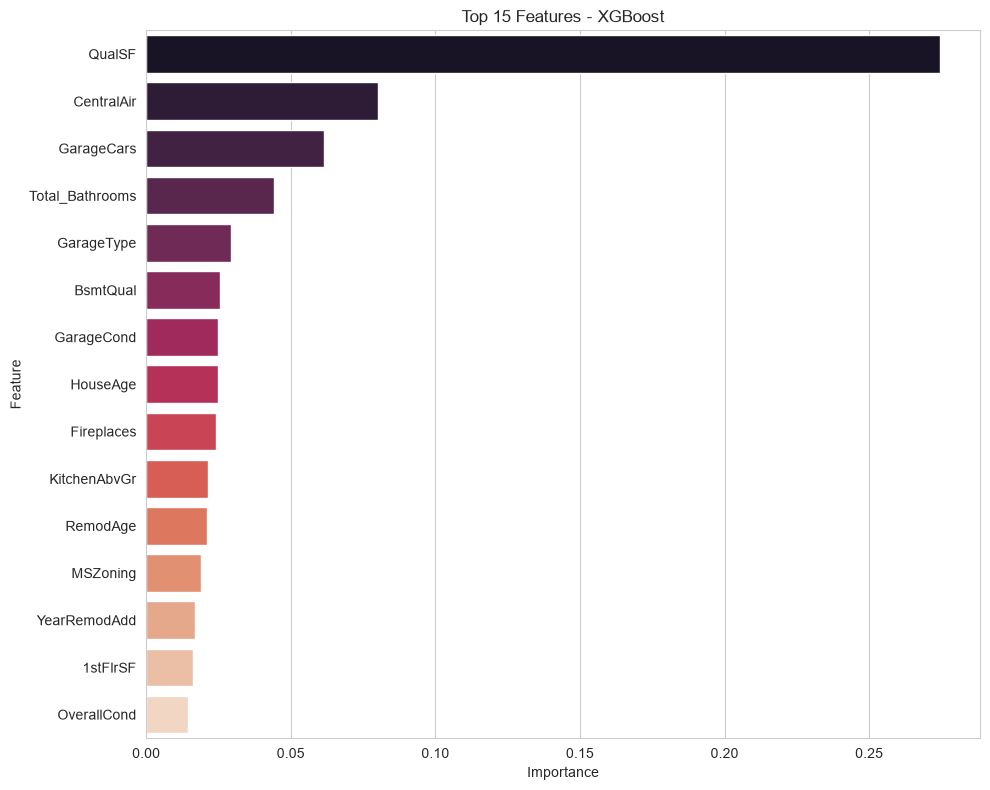

In [21]:
if hasattr(best_model, 'feature_importances_'):
    importance = pd.DataFrame({
        'Feature': X_train.columns,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)

    print("\n--- Top 15 Important Features ---")
    print(importance.head(15).to_string(index=False))

    plt.figure(figsize=(10, 8))
    sns.barplot(x='Importance', y='Feature', data=importance.head(15), palette='rocket')
    plt.title(f'Top 15 Features - {best_model_name}')
    plt.tight_layout()
    plt.savefig('07_feature_importance.png', dpi=150)
    plt.show()


 # STEP 8: SUBMISSION FILE



 Create Kaggle submission format: Id, SalePrice

In [22]:
submission = pd.DataFrame({'Id': test_ID, 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)
print("Submission file created: submission.csv")
print(submission.head())


Submission file created: submission.csv
     Id      SalePrice
0  1461  125818.578125
1  1462  158655.515625
2  1463  176223.421875
3  1464  190649.718750
4  1465  184281.750000



# FINAL MODEL COMPARISON - ALL REGRESSION METRICS


In [23]:
print("\n" + "=" * 80)
print("FINAL MODEL COMPARISON - ALL METRICS")
print("=" * 80)

from sklearn.base import clone

final_results = []

# Evaluate every model using the same 5-fold CV
for name, model in models.items():

    mae_scores = []
    mse_scores = []
    rmse_scores = []
    r2_scores = []

    for train_idx, val_idx in kf.split(X_train):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        # Create a fresh copy of the model
        model_copy = clone(model)

        # Train
        model_copy.fit(X_tr, y_tr)

        # Predict
        y_pred = model_copy.predict(X_val)

        # Metrics on log-transformed target
        mae_scores.append(mean_absolute_error(y_val, y_pred))
        mse_scores.append(mean_squared_error(y_val, y_pred))
        rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))
        r2_scores.append(r2_score(y_val, y_pred))

    final_results.append({
        'Model': name,
        'MAE': np.mean(mae_scores),
        'MSE': np.mean(mse_scores),
        'RMSE': np.mean(rmse_scores),
        'R²': np.mean(r2_scores)
    })

# Create comparison table
final_results_df = pd.DataFrame(final_results)

# Sort by RMSE - lower is better
final_results_df = final_results_df.sort_values('RMSE').reset_index(drop=True)

# Display table
print("\n--- MODEL PERFORMANCE COMPARISON ---")
display(
    final_results_df.style
    .format({
        'MAE': '{:.5f}',
        'MSE': '{:.5f}',
        'RMSE': '{:.5f}',
        'R²': '{:.5f}'
    })
)

# Identify best model
best_model_row = final_results_df.iloc[0]

print("\n" + "=" * 80)
print("🏆 BEST FITTED MODEL")
print("=" * 80)

print(f"Best Model : {best_model_row['Model']}")
print(f"MAE        : {best_model_row['MAE']:.5f}")
print(f"MSE        : {best_model_row['MSE']:.5f}")
print(f"RMSE       : {best_model_row['RMSE']:.5f}")
print(f"R² Score   : {best_model_row['R²']:.5f}")

print("\nSelection Criterion:")
print("Lower RMSE = Better Model")

print(f"\nTherefore, {best_model_row['Model']} is selected as the final model.")
print("=" * 80)


FINAL MODEL COMPARISON - ALL METRICS
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000962 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4050
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 82
[LightGBM] [Info] Start training from score 12.023362
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001292 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4051
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 83
[LightGBM] [Info] Start training from score 12.026498
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001282 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4056
[LightGBM] [Info] Number of data points in the train set: 1166, number of used fea

,Model,MAE,MSE,RMSE,R²
0,XGBoost,0.08081,0.01394,0.11797,0.91215
1,ElasticNet,0.08471,0.01417,0.11870,0.91070
2,Lasso,0.08474,0.01417,0.11870,0.91070
3,Ridge,0.08512,0.01430,0.11925,0.90996
4,LightGBM,0.08417,0.01526,0.12324,0.90430
5,GradientBoosting,0.08498,0.01527,0.12336,0.90423
6,RandomForest,0.09289,0.01814,0.13445,0.88563



🏆 BEST FITTED MODEL
Best Model : XGBoost
MAE        : 0.08081
MSE        : 0.01394
RMSE       : 0.11797
R² Score   : 0.91215

Selection Criterion:
Lower RMSE = Better Model

Therefore, XGBoost is selected as the final model.


# STEP 9: CONCLUSION

## Summary

1. **Problem:** Predict house prices in Ames, Iowa using 80 features.

2. **EDA:** Found skewed target variable, missing values, outliers, and strong correlations.

3. **Preprocessing:** Applied log transformation, outlier removal, missing-value imputation, feature engineering, categorical encoding, and feature scaling.

4. **Models:** Tested 7 machine learning models using 5-fold cross-validation.

5. **Best Model:** **XGBoost** achieved the lowest cross-validation RMSE of **0.11797**.

6. **Key Insight:** OverallQual and TotalSF were among the strongest predictors of house prices.

7. **Business Value:** The model can help buyers, sellers, and real-estate agents estimate house prices.

8. **Final Output:** Generated `submission.csv` containing predicted SalePrice values for the test dataset.

In [24]:
print("\n" + "=" * 60)
print("PROJECT COMPLETE")
print("=" * 60)

print(f"Best Model: {best_model_name}")
print(f"CV RMSE: {cv_results[best_model_name].mean():.5f}")

print("\nGenerated files:")
print(" - 01_target_distribution.png")
print(" - 02_missing_values.png")
print(" - 03_correlation.png")
print(" - 04_feature_relationships.png")
print(" - 05_outliers.png")
print(" - 06_model_comparison.png")
print(" - 07_feature_importance.png")
print(" - submission.csv")

print("\nFinal Model: XGBoost")
print("The XGBoost model was selected based on the lowest CV RMSE.")
print("=" * 60)


PROJECT COMPLETE
Best Model: XGBoost
CV RMSE: 0.11797

Generated files:
 - 01_target_distribution.png
 - 02_missing_values.png
 - 03_correlation.png
 - 04_feature_relationships.png
 - 05_outliers.png
 - 06_model_comparison.png
 - 07_feature_importance.png
 - submission.csv

Final Model: XGBoost
The XGBoost model was selected based on the lowest CV RMSE.
